In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
df = pd.read_csv('databasev4_2.csv')

X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])
Y = df['pos_y']

x_train, x_test, y_train, y_test, = train_test_split(X,Y,test_size=0.2,random_state=42)

**Random Forest Regressor**

In [3]:
mse = []
for i in np.arange(1,100,2):
    model_rf = RandomForestRegressor(n_estimators=i,random_state=42,n_jobs=4,)

    model_rf.fit(x_train,y_train)

    y_pred_rf = model_rf.predict(x_test)
    mse.append(mean_squared_error(y_test, y_pred_rf))

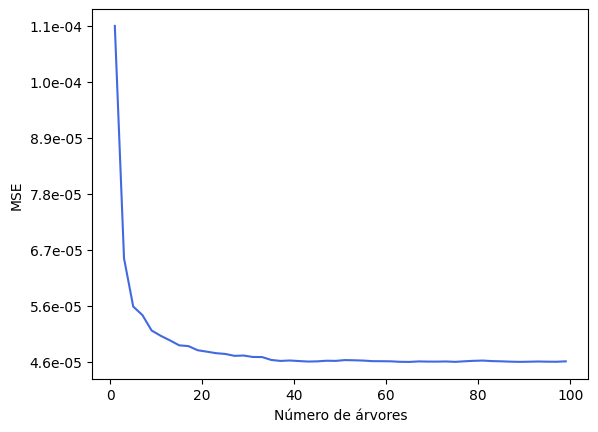

In [4]:
mse = np.array(mse)

ytik = np.linspace(mse.min(),mse.max(),7)

fig, ax = plt.subplots(1,1)

plt.xlabel('Número de árvores')
plt.ylabel('MSE')
plt.plot(np.arange(1,100,2),mse,color='royalblue')
xlabels = [f'{y:1.1e}' for y in ytik]
ax.set_yticks(ytik, labels=xlabels)
plt.show()

Resultado ótimo

In [5]:

model_rf = RandomForestRegressor(n_estimators=50,random_state=42,n_jobs=4,)

model_rf.fit(x_train,y_train)

y_pred_rf = model_rf.predict(x_test)

print('R²:', r2_score(y_test, y_pred_rf))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print('MAE:', mean_absolute_error(y_test, y_pred_rf))

R²: 0.7979924703224871
RMSE: 0.006772290782126316
MAE: 0.005327789473684209


**XGBoost**

In [6]:
mse_n_estimators = []
mse_learning_rate = []
mse_max_depth = []

for n in np.arange(2,102,2):
    model_xg = XGBRegressor(n_estimators=n, learning_rate=0.05, max_depth=6,
                    subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)
    model_xg.fit(x_train,y_train)

    y_pred_xg = model_xg.predict(x_test)
    mse_n_estimators.append(mean_squared_error(y_test, y_pred_xg))

for l in np.arange(0.01,0.201,0.001):
    model_xg = XGBRegressor(n_estimators=100, learning_rate=l, max_depth=6,
                    subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)
    model_xg.fit(x_train,y_train)

    y_pred_xg = model_xg.predict(x_test)
    mse_learning_rate.append(mean_squared_error(y_test, y_pred_xg))

for d in np.arange(1,21,1):
    model_xg = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=d,
                    subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)
    model_xg.fit(x_train,y_train)

    y_pred_xg = model_xg.predict(x_test)
    mse_max_depth.append(mean_squared_error(y_test, y_pred_xg))

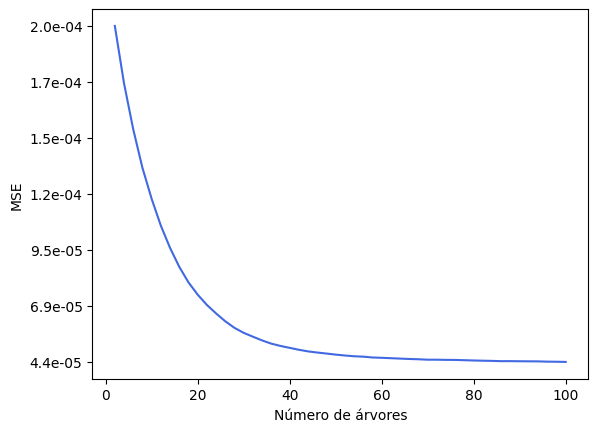

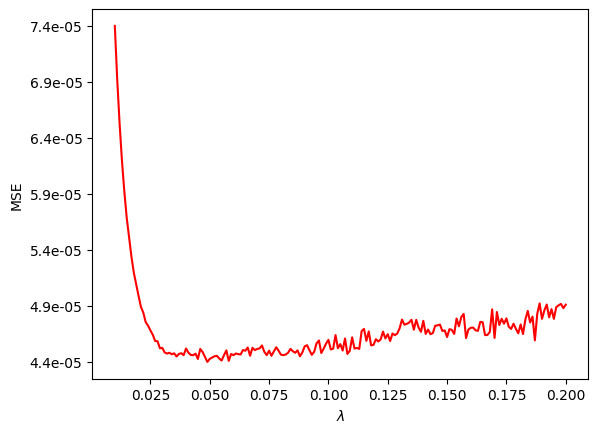

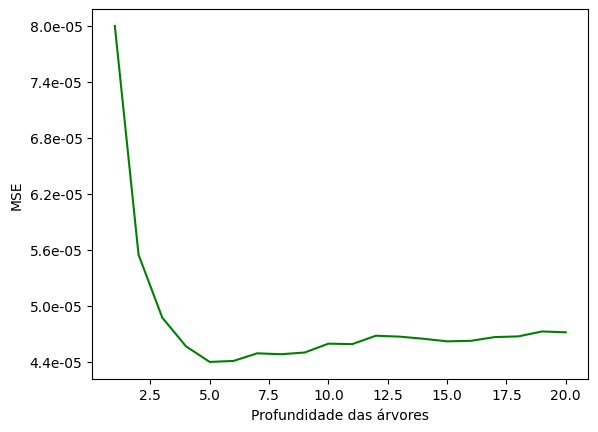

In [7]:
mse_n_estimators = np.array(mse_n_estimators)

ytik = np.linspace(mse_n_estimators.min(),mse_n_estimators.max(),7)

fig, ax = plt.subplots(1,1)

plt.xlabel('Número de árvores')
plt.ylabel('MSE')
plt.plot(np.arange(2,102,2),mse_n_estimators,color='royalblue')
xlabels = [f'{y:1.1e}' for y in ytik]
ax.set_yticks(ytik, labels=xlabels)
plt.show()

mse_learning_rate = np.array(mse_learning_rate)

ytik = np.linspace(mse_learning_rate.min(),mse_learning_rate.max(),7)

fig, ax = plt.subplots(1,1)

plt.xlabel(r'$\lambda$')
plt.ylabel('MSE')
plt.plot(np.arange(0.01,0.201,0.001),mse_learning_rate,color='red')
xlabels = [f'{y:1.1e}' for y in ytik]
ax.set_yticks(ytik, labels=xlabels)
plt.show()

mse_max_depth = np.array(mse_max_depth)

ytik = np.linspace(mse_max_depth.min(),mse_max_depth.max(),7)

fig, ax = plt.subplots(1,1)

plt.xlabel('Profundidade das árvores')
plt.ylabel('MSE')
plt.plot(np.arange(1,21,1),mse_max_depth,color='green')
xlabels = [f'{y:1.1e}' for y in ytik]
ax.set_yticks(ytik, labels=xlabels)
plt.show()

Resultado ótimo

In [8]:
model_xg = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5,
                    subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)

model_xg.fit(x_train,y_train)

y_pred_xg = model_xg.predict(x_test)

print('R²:', r2_score(y_test, y_pred_xg))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_xg)))
print('MAE:', mean_absolute_error(y_test, y_pred_xg))

R²: 0.8066845380845774
RMSE: 0.006624988275801133
MAE: 0.005239770157164646
